In [1]:
import pandas as pd

# load the data
df = pd.read_csv("../heart.csv")


# Process data
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['ExerciseAngina']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

cut_mapper = {'Down': 1, 'Flat': 2,'Up': 3}
df['ST_Slope'] = df['ST_Slope'].map(cut_mapper)

# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['Sex', 'ChestPainType', 'RestingECG']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)


df = df.drop(["Sex_F", "ChestPainType_TA", "RestingECG_LVH"], axis=1)




In [2]:
# this dataset is small, no need to sample

# take smaller sample since Fisher score is otherwise too heavy to calculate
# df = df.sample(7500)

# perform X/y -split
# if you  have more than one independent variable, list them all here
# leave out the target variable! (dependent variable)

# this is a nice and common trick => everything EXCEPT target variable => support variable
X = df.drop("HeartDisease", axis=1)

# have only the target variable here (dependent variable)
y = df["HeartDisease"]

#### Fisher score can be super slow with large datasets, you might want to take a smaller sample before attempting it!

<Axes: >

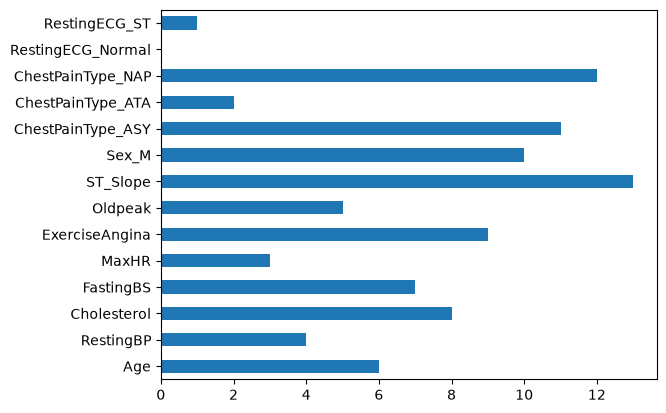

In [3]:
# Fisher score to important variables in the dataset
# pip install skfeature-chappers
from skfeature.function.similarity_based import fisher_score

# get the fisher's score rankings 
ranks = fisher_score.fisher_score(X.values, y.values)

# create a pandas DataFrame for easier interpretation
feat_importances = pd.Series(ranks, X.columns)
feat_importances.plot(kind='barh')

# how to interpret -> low score means the effect of this field is not large in the dataset
# => typically means other columns in the dataset have similar correlations/connections, 
# therefore making this particular column not so useful since other columns 
# already fill this role for this correlation

# Fisher's score studies the variance of the data -> statistical significance